# Практическая работа 6. RAGAS

В работе рассматривается оценка качества RAG-систем с помощью Ragas.

### Задание 1. Проверка RAG и сохранение датасета

Подготовим вопросы и контексты из PDF-документов, получим ответы GigaChat и сохраним результаты в Pandas и Langfuse для дальнейшего анализа.

In [ ]:
!pip install -q pypdf gigachat langfuse pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [ ]:
import os
import pandas as pd

from pathlib import Path
from pypdf import PdfReader
from google.colab import userdata
from gigachat import GigaChat
from langfuse import get_client

for key in [
    "LANGFUSE_SECRET_KEY",
    "LANGFUSE_PUBLIC_KEY",
    "LANGFUSE_BASE_URL",
]:
    os.environ[key] = userdata.get(key)

langfuse = get_client()

gigachat_client = GigaChat(
    credentials=userdata.get("GIGACHAT_CREDENTIALS"),
    scope="GIGACHAT_API_PERS",
    base_url="https://api.giga.chat/v1",
    verify_ssl_certs=False,
)

MODEL = "GigaChat-2"

В папку `/content/docs/` загружены 3 pdf-файла для вопросов об аудите информационной безопасности, хронической бедности и руководстве PowerPoint.  

Функция для извлечения текста конкретной страницы:

In [ ]:
DATA_DIR = Path("/content/docs")

def get_page_text(filename, page_index):
    reader = PdfReader(DATA_DIR / filename)
    return reader.pages[page_index].extract_text() or ""

Теперь создадим шесть тестовых примеров с эталонными ответами:

In [ ]:
rag_items = [
    {
        "question": "What was the overall audit opinion?",
        "contexts": [get_page_text("0007-pdf.pdf", 0)],
        "ground_truth": "Reasonable Assurance.",
    },
    {
        "question": "What security weaknesses were found at West Offices and Hazel Court?",
        "contexts": [get_page_text("0007-pdf.pdf", 2)],
        "ground_truth": (
            "Some cupboards containing sensitive information were left unlocked, "
            "confidential documents were not always stored securely, "
            "and assets such as laptops, cameras and keys were unsecured."
        ),
    },
    {
        "question": "What is the defining characteristic of chronic poverty?",
        "contexts": [get_page_text("0008-pdf.pdf", 1)],
        "ground_truth": (
            "Long duration is both necessary and sufficient "
            "for poverty to be considered chronic."
        ),
    },
    {
        "question": "What five categories of poverty are proposed in the paper?",
        "contexts": [get_page_text("0008-pdf.pdf", 1)],
        "ground_truth": (
            "Always poor, usually poor, churning poor, "
            "occasionally poor and never poor."
        ),
    },
    {
        "question": "What tasks are covered in the PowerPoint 2010 training guide?",
        "contexts": [get_page_text("0009-pdf.pdf", 1)],
        "ground_truth": (
            "Planning and designing presentations, creating blank presentations, "
            "using templates and themes, entering text, saving presentations, "
            "inserting slides and previewing slide shows."
        ),
    },
    {
        "question": "What are the main design principles recommended for PowerPoint slides?",
        "contexts": [get_page_text("0009-pdf.pdf", 4)],
        "ground_truth": (
            "Keep text concise, use readable fonts, limit colours, "
            "maintain adequate white space and ensure a consistent design."
        ),
    },
]

print("Questions:", len(rag_items))

for item in rag_items:
    print(
        item["question"],
        "| context chars:", len(item["contexts"][0])
    )

Questions: 6
What was the overall audit opinion? | context chars: 428
What security weaknesses were found at West Offices and Hazel Court? | context chars: 2639
What is the defining characteristic of chronic poverty? | context chars: 3530
What five categories of poverty are proposed in the paper? | context chars: 3530
What tasks are covered in the PowerPoint 2010 training guide? | context chars: 1299
What are the main design principles recommended for PowerPoint slides? | context chars: 2943


### Генерация ответов

Для каждого вопроса передаём модели заранее выбранный контекст из документа. Модель должна использовать только содержащуюся в нём информацию и не придумывать дополнительные факты.

In [ ]:
def generate_rag_answer(question, contexts):
    context_text = "\n\n".join(contexts)

    response = gigachat_client.chat({
        "model": MODEL,
        "messages": [
            {
                "role": "system",
                "content": (
                    "Answer the question using only the provided context. "
                    "If the answer is not present, say so. "
                    "Keep the answer concise."
                ),
            },
            {
                "role": "user",
                "content": (
                    f"Context:\n{context_text}\n\n"
                    f"Question: {question}"
                ),
            },
        ],
        "temperature": 0,
        "max_tokens": 300,
    })

    return response.choices[0].message.content

Прогоним наши примеры:

In [ ]:
rag_results = []

for i, item in enumerate(rag_items, start=1):
    answer = generate_rag_answer(item["question"], item["contexts"])

    rag_results.append({**item, "answer": answer})

    print(f"{i}/6 | {item['question']}")
    print("Answer:", answer)
    print()

1/6 | What was the overall audit opinion?
Answer: The overall audit opinion was "Reasonable Assurance."

2/6 | What security weaknesses were found at West Offices and Hazel Court?
Answer: At West Offices, some cupboards containing sensitive, personal, or confidential information were unsecured, with only a small number of documents not stored in cupboards. At Hazel Court, some cupboards containing personal and sensitive information were left unlocked, and sensitive information was left on desks or on open storage. Additionally, across both sites, many council assets such as laptops, cameras, and keys to properties and vehicles were left unsecured.

3/6 | What is the defining characteristic of chronic poverty?
Answer: The defining characteristic of chronic poverty is long duration.

4/6 | What five categories of poverty are proposed in the paper?
Answer: The five categories of poverty proposed in the paper are:
1. Always poor
2. Usually poor
3. Churning poor
4. Occasionally poor
5. Neve

In [ ]:
rag_df = pd.DataFrame(rag_results)

print("Rows:", len(rag_df))
print("Missing values:")
print(rag_df.isna().sum())

rag_df[["question", "answer", "ground_truth"]]

Rows: 6
Missing values:
question        0
contexts        0
ground_truth    0
answer          0
dtype: int64


,question,answer,ground_truth
0,What was the overall audit opinion?,"The overall audit opinion was ""Reasonable Assu...",Reasonable Assurance.
1,What security weaknesses were found at West Of...,"At West Offices, some cupboards containing sen...",Some cupboards containing sensitive informatio...
2,What is the defining characteristic of chronic...,The defining characteristic of chronic poverty...,Long duration is both necessary and sufficient...
3,What five categories of poverty are proposed i...,The five categories of poverty proposed in the...,"Always poor, usually poor, churning poor, occa..."
4,What tasks are covered in the PowerPoint 2010 ...,The tasks covered in the PowerPoint 2010 train...,"Planning and designing presentations, creating..."
5,What are the main design principles recommende...,The main design principles recommended for Pow...,"Keep text concise, use readable fonts, limit c..."


Загружаем результаты в Langfuse. Сохраним вопрос и контексты во входных данных, эталон - в ожидаемом ответе, а фактический ответ модели - в metadata.

In [ ]:
DATASET_NAME = "practice-6-rag-results"

langfuse.create_dataset(
    name=DATASET_NAME,
    description="RAG questions, contexts and GigaChat answers",
)

for row in rag_results:
    langfuse.create_dataset_item(
        dataset_name=DATASET_NAME,
        input={
            "question": row["question"],
            "contexts": row["contexts"],
        },
        expected_output={
            "ground_truth": row["ground_truth"],
        },
        metadata={
            "answer": row["answer"],
            "model": MODEL,
        },
    )

langfuse.flush()

print("Uploaded:", len(rag_results))

Uploaded: 6


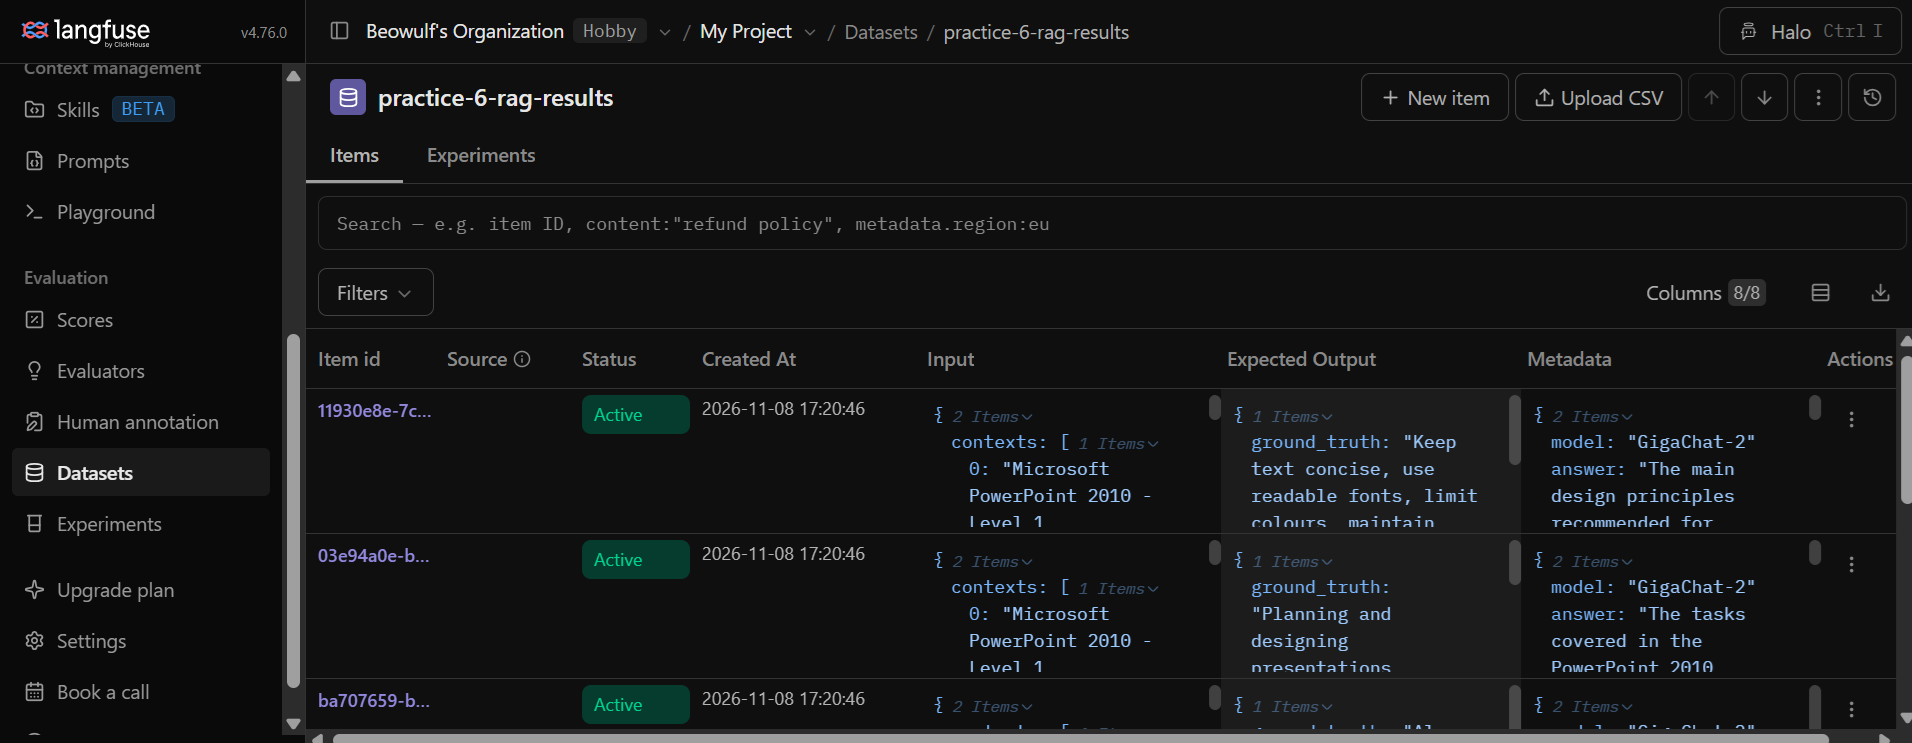

### Вывод

Подготовлен набор из 6 вопросов по трём PDF-документам. Для каждого вопроса задан контекст и эталонный ответ, после чего получен ответ GigaChat-2.

Все ответы оказались содержательно корректными и соответствовали исходным документам. Результаты сохранены в Pandas DataFrame и загружены в Langfuse.

Таким образом, подготовлен небольшой тестовый набор данных, который можно использовать для дальнейшей оценки качества RAG-систем.

## Задание 2. Влияние chunking и embedding-моделей

Сравним три размера чанков и две embedding-модели на одинаковых вопросах.

Для каждой конфигурации измерим скорость поиска и генерации, сохраним найденные контексты и ответы GigaChat. Затем оценим качество с помощью четырёх метрик Ragas и выберем наиболее удачную комбинацию.

In [ ]:
!pip install -q "langchain-community==0.3.31"

In [9]:
!pip install -q sentence-transformers ragas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


Сохраним извлечённые страницы в памяти, чтобы при смене размера чанков повторно не читать PDF.

In [10]:
import time
import numpy as np

from sentence_transformers import SentenceTransformer

pdf_files = [
    "0007-pdf.pdf",
    "0008-pdf.pdf",
    "0009-pdf.pdf",
]

pages_data = []

for filename in pdf_files:
    reader = PdfReader(DATA_DIR / filename)

    for page_index, page in enumerate(reader.pages):
        text = page.extract_text() or ""

        if text.strip():
            pages_data.append({"source": filename, "page": page_index, "text": text})

print("Pages loaded:", len(pages_data))

Pages loaded: 60


Сделаем простое разбиение по символам с overlap. Способ разбиения будет одинаковым, меняются только размеры.

In [11]:
def make_chunks(pages, chunk_size, overlap):
    result = []

    for page in pages:
        text = page["text"]
        step = chunk_size - overlap

        for start in range(0, len(text), step):
            chunk = text[start:start + chunk_size].strip()

            if chunk:
                result.append({
                    "text": chunk,
                    "source": page["source"],
                    "page": page["page"],
                })

    return result

In [12]:
chunk_settings = {
    "small": (400, 100),
    "medium": (800, 150),
    "large": (1400, 200),
}

chunk_sets = {}

for name, (size, overlap) in chunk_settings.items():
    chunk_sets[name] = make_chunks(pages_data, size, overlap)

    print(
        f"{name:6} | "
        f"chunk_size={size:4} | "
        f"overlap={overlap:3} | "
        f"chunks={len(chunk_sets[name])}"
    )

small  | chunk_size= 400 | overlap=100 | chunks=538
medium | chunk_size= 800 | overlap=150 | chunks=267
large  | chunk_size=1400 | overlap=200 | chunks=161


Выберем две компактные эмбеддинг-модели:

In [13]:
embedding_models = {
    "MiniLM": SentenceTransformer(
        "sentence-transformers/all-MiniLM-L6-v2",
        device="cpu",
    ),
    "E5": SentenceTransformer(
        "intfloat/multilingual-e5-small",
        device="cpu",
    ),
}

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (17 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Выполним индексацию для всех шести комбинаций. Эмбеддинги нормализуем, чтобы косинусное сходство вычислялось через скалярное произведение.

In [14]:
vector_indexes = {}
indexing_results = []

for chunk_name, chunks_data in chunk_sets.items():

    texts = [chunk["text"] for chunk in chunks_data]

    for model_name, model in embedding_models.items():

        start = time.perf_counter()

        if model_name == "E5":
            input_texts = ["passage: " + text for text in texts]
        else:
            input_texts = texts

        vectors = model.encode(
            input_texts,
            convert_to_numpy=True,
            normalize_embeddings=True,
            show_progress_bar=False,
        )

        elapsed = time.perf_counter() - start

        key = (chunk_name, model_name)

        vector_indexes[key] = {
            "vectors": vectors,
            "chunks": chunks_data,
        }

        indexing_results.append({
            "chunk_size": chunk_name,
            "embedding_model": model_name,
            "chunks": len(chunks_data),
            "indexing_time_sec": elapsed,
        })

        print(
            f"{chunk_name:6} + {model_name:6} | "
            f"{len(chunks_data):4} chunks | "
            f"{elapsed:.2f} sec"
        )

small  + MiniLM |  538 chunks | 28.26 sec
small  + E5     |  538 chunks | 63.26 sec
medium + MiniLM |  267 chunks | 33.73 sec
medium + E5     |  267 chunks | 57.76 sec
large  + MiniLM |  161 chunks | 19.21 sec
large  + E5     |  161 chunks | 57.99 sec


In [15]:
indexing_df = pd.DataFrame(indexing_results)
indexing_df

,chunk_size,embedding_model,chunks,indexing_time_sec
0,small,MiniLM,538,28.263009
1,small,E5,538,63.262120
2,medium,MiniLM,267,33.732596
3,medium,E5,267,57.756717
4,large,MiniLM,161,19.209712
5,large,E5,161,57.990190


Реализуем поиск топ-3. Используем простое косинусное сходство. Поскольку векторы уже нормализованы, достаточно операции vectors @ query_vector.

In [16]:
def retrieve_contexts(question, chunk_name, model_name, k=3):
    model = embedding_models[model_name]
    index = vector_indexes[(chunk_name, model_name)]

    query = (
        "query: " + question
        if model_name == "E5"
        else question
    )

    start = time.perf_counter()

    query_vector = model.encode(query, convert_to_numpy=True, normalize_embeddings=True)

    scores = index["vectors"] @ query_vector
    top_indices = np.argsort(scores)[::-1][:k]

    elapsed = time.perf_counter() - start

    contexts = [index["chunks"][i]["text"] for i in top_indices]

    sources = [(index["chunks"][i]["source"], index["chunks"][i]["page"]) for i in top_indices]

    return contexts, sources, elapsed

Проверим поиск на всех конфигурациях. Для быстрой проверки используем один вопрос из задания 1 (вопрос о недостатках информационной безопасности в West Offices и Hazel Court).

In [17]:
test_question = rag_items[1]["question"]

print("QUESTION:", test_question)

for chunk_name in chunk_settings:
    for model_name in embedding_models:

        contexts, sources, elapsed = retrieve_contexts(test_question, chunk_name, model_name, k=3)

        print("\n" + "=" * 70)
        print(f"CONFIG: {chunk_name} + {model_name}")
        print(f"Retrieval time: {elapsed:.3f} sec")

        for rank, (source, page) in enumerate(sources, start=1):
            print(f"{rank}. {source}, page {page + 1}")

QUESTION: What security weaknesses were found at West Offices and Hazel Court?

CONFIG: small + MiniLM
Retrieval time: 0.067 sec
1. 0007-pdf.pdf, page 3
2. 0007-pdf.pdf, page 3
3. 0007-pdf.pdf, page 3

CONFIG: small + E5
Retrieval time: 0.138 sec
1. 0007-pdf.pdf, page 3
2. 0007-pdf.pdf, page 2
3. 0007-pdf.pdf, page 3

CONFIG: medium + MiniLM
Retrieval time: 0.066 sec
1. 0007-pdf.pdf, page 3
2. 0007-pdf.pdf, page 3
3. 0007-pdf.pdf, page 2

CONFIG: medium + E5
Retrieval time: 0.069 sec
1. 0007-pdf.pdf, page 3
2. 0007-pdf.pdf, page 2
3. 0007-pdf.pdf, page 3

CONFIG: large + MiniLM
Retrieval time: 0.061 sec
1. 0007-pdf.pdf, page 3
2. 0007-pdf.pdf, page 3
3. 0007-pdf.pdf, page 2

CONFIG: large + E5
Retrieval time: 0.105 sec
1. 0007-pdf.pdf, page 3
2. 0007-pdf.pdf, page 3
3. 0007-pdf.pdf, page 2


### Генерация ответов RAG

Для шести конфигураций поиска получаем ответы на одинаковые шесть вопросов.

Используем одну модель GigaChat-2 и одинаковые параметры генерации. Результаты сохраняем для последующей оценки метриками Ragas.

In [18]:
rag_experiment_results = []

for chunk_name in chunk_settings:
    for model_name in embedding_models:

        config_name = f"{chunk_name}_{model_name}"
        print(f"\nCONFIG: {config_name}")

        for item in rag_items:
            question = item["question"]

            contexts, sources, retrieval_time = retrieve_contexts(
                question,
                chunk_name,
                model_name,
                k=3,
            )

            start = time.perf_counter()

            answer = generate_rag_answer(question, contexts)

            generation_time = time.perf_counter() - start

            rag_experiment_results.append({
                "config": config_name,
                "user_input": question,
                "retrieved_contexts": contexts,
                "response": answer,
                "reference": item["ground_truth"],
                "retrieval_time_sec": retrieval_time,
                "generation_time_sec": generation_time,
                "total_time_sec": retrieval_time + generation_time,
                "sources": sources,
            })

            print(
                f"{len(rag_experiment_results):02d}/36 | "
                f"retrieval={retrieval_time:.3f}s | "
                f"generation={generation_time:.2f}s"
            )

print("\nВсего результатов:", len(rag_experiment_results))


CONFIG: small_MiniLM
01/36 | retrieval=0.029s | generation=1.69s
02/36 | retrieval=0.021s | generation=0.74s
03/36 | retrieval=0.020s | generation=0.42s
04/36 | retrieval=0.020s | generation=0.76s
05/36 | retrieval=0.021s | generation=0.57s
06/36 | retrieval=0.038s | generation=1.36s

CONFIG: small_E5
07/36 | retrieval=0.055s | generation=0.44s
08/36 | retrieval=0.067s | generation=0.87s
09/36 | retrieval=0.037s | generation=0.54s
10/36 | retrieval=0.039s | generation=1.30s
11/36 | retrieval=0.054s | generation=0.49s
12/36 | retrieval=0.041s | generation=1.29s

CONFIG: medium_MiniLM
13/36 | retrieval=0.024s | generation=0.45s
14/36 | retrieval=0.021s | generation=0.92s
15/36 | retrieval=0.020s | generation=0.58s
16/36 | retrieval=0.022s | generation=0.72s
17/36 | retrieval=0.022s | generation=0.49s
18/36 | retrieval=0.021s | generation=1.85s

CONFIG: medium_E5
19/36 | retrieval=0.034s | generation=0.42s
20/36 | retrieval=0.064s | generation=9.74s
21/36 | retrieval=0.051s | generation=

In [19]:
rag_experiment_df = pd.DataFrame(rag_experiment_results)

rag_experiment_df.to_json(
    "/content/rag_experiment_results.json",
    orient="records",
    force_ascii=False,
    indent=2,
)

print("Rows:", len(rag_experiment_df))

rag_experiment_df[["config", "user_input", "retrieval_time_sec", "generation_time_sec", "total_time_sec"]]

Rows: 36


,config,user_input,retrieval_time_sec,generation_time_sec,total_time_sec
0,small_MiniLM,What was the overall audit opinion?,0.029409,1.688827,1.718236
1,small_MiniLM,What security weaknesses were found at West Of...,0.020535,0.738772,0.759306
2,small_MiniLM,What is the defining characteristic of chronic...,0.019730,0.416472,0.436202
3,small_MiniLM,What five categories of poverty are proposed i...,0.020434,0.760723,0.781157
4,small_MiniLM,What tasks are covered in the PowerPoint 2010 ...,0.020664,0.567695,0.588360
5,small_MiniLM,What are the main design principles recommende...,0.037864,1.360419,1.398283
6,small_E5,What was the overall audit opinion?,0.054852,0.437355,0.492207
7,small_E5,What security weaknesses were found at West Of...,0.066778,0.866444,0.933223
8,small_E5,What is the defining characteristic of chronic...,0.036874,0.543237,0.580111
9,small_E5,What five categories of poverty are proposed i...,0.038880,1.301236,1.340116


Сравниваем время:

In [20]:
timing_summary = (
    rag_experiment_df
    .groupby("config")
    .agg(
        requests=("config", "count"),
        avg_retrieval_sec=("retrieval_time_sec", "mean"),
        avg_generation_sec=("generation_time_sec", "mean"),
        avg_total_sec=("total_time_sec", "mean"),
    )
    .round(3)
)

timing_summary

,requests,avg_retrieval_sec,avg_generation_sec,avg_total_sec
config,,,,
large_E5,6,0.039,0.865,0.903
large_MiniLM,6,0.025,0.888,0.913
medium_E5,6,0.044,2.088,2.132
medium_MiniLM,6,0.022,0.835,0.857
small_E5,6,0.049,0.821,0.869
small_MiniLM,6,0.025,0.922,0.947


Для оценки содержания ответов выведем их по конфигурациям:

In [21]:
for row in rag_experiment_results:
    print("\n" + "=" * 80)
    print("CONFIG:", row["config"])
    print("QUESTION:", row["user_input"])
    print("ANSWER:", row["response"])


CONFIG: small_MiniLM
QUESTION: What was the overall audit opinion?
ANSWER: The overall audit opinion was "Reasonable Assurance."

CONFIG: small_MiniLM
QUESTION: What security weaknesses were found at West Offices and Hazel Court?
ANSWER: At West Offices, the security weaknesses included unsecured cupboards with sensitive, personal, or confidential information, as well as a few documents left out on desks or in other unsecured locations. At Hazel Court, similar issues were observed, such as unlocked cupboards containing personal and sensitive information.

CONFIG: small_MiniLM
QUESTION: What is the defining characteristic of chronic poverty?
ANSWER: The defining characteristic of chronic poverty is long duration.

CONFIG: small_MiniLM
QUESTION: What five categories of poverty are proposed in the paper?
ANSWER: The five categories of poverty proposed in the paper are: always poor, usually poor, churning poor, occasionally poor, and never poor.

CONFIG: small_MiniLM
QUESTION: What tasks 

### Оценка качества RAG с помощью Ragas

Для оценки используем GigaChat-2 в роли LLM-судьи. Рассчитаем четыре метрики качества: Faithfulness, Answer Relevancy, Context Precision и Context Recall.

In [ ]:
!pip install -q langchain-gigachat

In [14]:
import pandas as pd
import time
from pathlib import Path
from google.colab import userdata

from langchain_gigachat.chat_models import GigaChat as ChatGigaChat
from ragas.llms import LangchainLLMWrapper
from ragas.dataset_schema import SingleTurnSample

judge_model = ChatGigaChat(
    credentials=userdata.get("GIGACHAT_CREDENTIALS"),
    scope="GIGACHAT_API_PERS",
    model="GigaChat-2",
    verify_ssl_certs=False,
    temperature=0,
)

ragas_llm = LangchainLLMWrapper(judge_model)

print("GigaChat judge initialized")

GigaChat judge initialized


/tmp/ipykernel_31471/1432383456.py:18: DeprecationWarning: LangchainLLMWrapper is deprecated and will be removed in a future version. Use llm_factory instead: from openai import OpenAI; from ragas.llms import llm_factory; llm = llm_factory('gpt-4o-mini', client=OpenAI(api_key='...'))
  ragas_llm = LangchainLLMWrapper(judge_model)


### Метрики качества

Faithfulness оценивает достоверность ответа относительно найденных контекстов, Answer Relevancy — соответствие вопросу, Context Precision - релевантность и порядок найденных фрагментов, Context Recall - полноту информации для эталонного ответа.

Для Answer Relevancy используем одну и ту же локальную embedding-модель во всех конфигурациях.

In [15]:
from langchain_community.embeddings import HuggingFaceEmbeddings
from ragas.embeddings import LangchainEmbeddingsWrapper

from ragas.metrics import (
    Faithfulness,
    ResponseRelevancy,
    LLMContextPrecisionWithReference,
    LLMContextRecall,
)

evaluation_embeddings = LangchainEmbeddingsWrapper(
    HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        model_kwargs={"device": "cpu"},
    )
)

metrics = {
    "faithfulness": Faithfulness(llm=ragas_llm),
    "answer_relevancy": ResponseRelevancy(
        llm=ragas_llm,
        embeddings=evaluation_embeddings,
        strictness=1,
    ),
    "context_precision": LLMContextPrecisionWithReference(
        llm=ragas_llm,
    ),
    "context_recall": LLMContextRecall(
        llm=ragas_llm,
    ),
}

print("Metrics configured:", list(metrics))

/tmp/ipykernel_31471/3848586572.py:4: DeprecationWarning: Importing Faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import (
/tmp/ipykernel_31471/3848586572.py:4: DeprecationWarning: Importing ResponseRelevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import ResponseRelevancy
  from ragas.metrics import (
/tmp/ipykernel_31471/3848586572.py:4: DeprecationWarning: Importing LLMContextPrecisionWithReference from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import LLMContextPrecisionWithReference
  from ragas.metrics import (
/tmp/ipykernel_31471/3848586572.py:4: DeprecationWarning: Importing LLMContextRecall from 'ragas.metr

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Metrics configured: ['faithfulness', 'answer_relevancy', 'context_precision', 'context_recall']


/tmp/ipykernel_31471/3848586572.py:11: DeprecationWarning: LangchainEmbeddingsWrapper is deprecated and will be removed in a future version. Use the modern embedding providers instead: embedding_factory('openai', model='text-embedding-3-small', client=openai_client) or from ragas.embeddings import OpenAIEmbeddings, GoogleEmbeddings, HuggingFaceEmbeddings
  evaluation_embeddings = LangchainEmbeddingsWrapper(


### Последовательная оценка

Из-за ограничений GigaChat API (WARNING:gigachat.api.utils:Rate limit exceeded (429)) метрики рассчитываются последовательно, с паузами между вызовами. Промежуточные результаты сохраняются в CSV, чтобы при ошибках можно было продолжить с последней успешной оценки.

In [21]:
import math

SCORES_PATH = Path("/content/ragas_scores_progress.csv")

# Сначала проверяем два ответа
MAX_ROWS = len(rag_experiment_results)

# Пауза между обращениями к Ragas
PAUSE_SEC = 10

if SCORES_PATH.exists():
    scores = pd.read_csv(SCORES_PATH).to_dict("records")
else:
    scores = []

completed = {(int(row["row_id"]), row["metric"]) for row in scores if pd.notna(row["score"])}

stopped = False

for i, row in enumerate(rag_experiment_results[:MAX_ROWS]):

    sample = SingleTurnSample(
        user_input=row["user_input"],
        retrieved_contexts=row["retrieved_contexts"],
        response=row["response"],
        reference=row["reference"],
    )

    for metric_name, metric in metrics.items():

        if (i, metric_name) in completed:
            continue

        try:
            value = float(metric.single_turn_score(sample))

            if not math.isfinite(value):
                raise ValueError("Ragas returned NaN or infinity")

            scores.append({"row_id": i, "config": row["config"], "metric": metric_name, "score": value})

            pd.DataFrame(scores).to_csv(SCORES_PATH, index=False)

            completed.add((i, metric_name))

            print(
                f"[{i + 1}/{MAX_ROWS}] "
                f"{row['config']} | "
                f"{metric_name}: {value:.4f}",
                flush=True,
            )

            time.sleep(PAUSE_SEC)

        except Exception as e:
            print(
                f"\nОстановка: пример {i + 1}, "
                f"метрика {metric_name}\n"
                f"{type(e).__name__}: {e}"
            )
            stopped = True
            break

    if stopped:
        break

print(f"\nСохранено оценок: {len(scores)}")

[3/36] small_MiniLM | faithfulness: 1.0000
[3/36] small_MiniLM | answer_relevancy: 0.9204
[3/36] small_MiniLM | context_precision: 0.3333
[3/36] small_MiniLM | context_recall: 1.0000
[4/36] small_MiniLM | faithfulness: 0.6000
[4/36] small_MiniLM | answer_relevancy: 0.9702
[4/36] small_MiniLM | context_precision: 1.0000
[4/36] small_MiniLM | context_recall: 1.0000
[5/36] small_MiniLM | faithfulness: 1.0000
[5/36] small_MiniLM | answer_relevancy: 0.0000
[5/36] small_MiniLM | context_precision: 1.0000
[5/36] small_MiniLM | context_recall: 1.0000
[6/36] small_MiniLM | faithfulness: 0.8333
[6/36] small_MiniLM | answer_relevancy: 0.9698
[6/36] small_MiniLM | context_precision: 1.0000
[6/36] small_MiniLM | context_recall: 1.0000
[7/36] small_E5 | faithfulness: 1.0000
[7/36] small_E5 | answer_relevancy: 0.7952
[7/36] small_E5 | context_precision: 0.5833
[7/36] small_E5 | context_recall: 1.0000
[8/36] small_E5 | faithfulness: 0.7500
[8/36] small_E5 | answer_relevancy: 0.8440
[8/36] small_E5 | c

In [22]:
scores_df = pd.read_csv(SCORES_PATH)

print("Всего оценок:", len(scores_df))
print("Пропущенных значений:", scores_df["score"].isna().sum())

display(scores_df.tail(10))

Всего оценок: 144
Пропущенных значений: 0


,row_id,config,metric,score
134,33,large_E5,context_precision,0.583333
135,33,large_E5,context_recall,1.000000
136,34,large_E5,faithfulness,1.000000
137,34,large_E5,answer_relevancy,0.000000
138,34,large_E5,context_precision,0.583333
139,34,large_E5,context_recall,0.714286
140,35,large_E5,faithfulness,1.000000
141,35,large_E5,answer_relevancy,0.958552
142,35,large_E5,context_precision,1.000000
143,35,large_E5,context_recall,1.000000


### Результаты оценки Ragas

Получено 144 оценки: по четыре метрики для каждого из 36 ответов. Проверим полноту результатов и отсутствие пропусков перед сравнением конфигураций.

In [23]:
import pandas as pd

scores_df = pd.read_csv("/content/ragas_scores_progress.csv")

print("Всего оценок:", len(scores_df))
print("Пропуски:", scores_df.isna().sum().sum())
print("Дубликаты:", scores_df.duplicated(["row_id", "metric"]).sum())

assert len(scores_df) == 144
assert scores_df.isna().sum().sum() == 0
assert scores_df.duplicated(["row_id", "metric"]).sum() == 0
assert scores_df["score"].between(0, 1).all()

print("Проверка пройдена")

Всего оценок: 144
Пропуски: 0
Дубликаты: 0
Проверка пройдена


### Сравнение конфигураций

Рассчитаем средние значения метрик Ragas и время работы для каждой комбинации размера чанков и embedding-модели. Это позволит сравнить не только качество ответов, но и скорость RAG-системы.

In [24]:
# Переводим оценки метрик в отдельные колонки
quality_df = (
    scores_df
    .pivot(index="row_id", columns="metric", values="score")
    .reset_index()
)

# Добавляем время поиска и генерации
timing_df = pd.DataFrame([
    {
        "row_id": i,
        "config": row["config"],
        "retrieval_time_sec": row["retrieval_time_sec"],
        "generation_time_sec": row["generation_time_sec"],
        "total_time_sec": row["total_time_sec"],
    }
    for i, row in enumerate(rag_experiment_results)
])

results_df = quality_df.merge(timing_df, on="row_id", validate="one_to_one")

# Усредняем показатели по конфигурациям
comparison_df = (
    results_df
    .groupby("config")
    .agg(
        faithfulness=("faithfulness", "mean"),
        answer_relevancy=("answer_relevancy", "mean"),
        context_precision=("context_precision", "mean"),
        context_recall=("context_recall", "mean"),
        retrieval_sec=("retrieval_time_sec", "mean"),
        generation_sec=("generation_time_sec", "mean"),
        total_sec=("total_time_sec", "mean"),
    )
    .round(3)
)

display(comparison_df)

,faithfulness,answer_relevancy,context_precision,context_recall,retrieval_sec,generation_sec,total_sec
config,,,,,,,
large_E5,0.933,0.737,0.861,0.952,0.039,0.865,0.903
large_MiniLM,0.750,0.743,0.833,0.776,0.025,0.888,0.913
medium_E5,1.000,0.749,0.861,0.972,0.044,2.088,2.132
medium_MiniLM,0.844,0.752,0.764,1.000,0.022,0.835,0.857
small_E5,0.958,0.907,0.653,0.911,0.049,0.821,0.869
small_MiniLM,0.850,0.773,0.792,1.000,0.025,0.922,0.947


In [25]:
results_df.to_csv("/content/ragas_detailed_results.csv", index=False)
comparison_df.to_csv("/content/ragas_comparison.csv")
print("Результаты сохранены")

Результаты сохранены


### Вывод

Сравнили 6 конфигураций RAG: три размера чанков (400, 800 и 1400 символов) и две embedding-модели (MiniLM и E5). Для каждой конфигурации проверили 6 одинаковых вопросов и рассчитали четыре метрики Ragas.

По результатам оценки:

- **small + E5** показала лучший Answer Relevancy (0.907) и высокую Faithfulness (0.958).
- **medium + E5** достигла максимальной Faithfulness (1.000) и одной из лучших Context Precision (0.861).
- **large + MiniLM** показала наиболее слабые результаты по Faithfulness (0.750) и Context Recall (0.776).
- Время поиска во всех конфигурациях было небольшим — примерно 0.02–0.05 секунды. Основную часть общего времени занимала генерация ответа.

По совокупности результатов наиболее интересными оказались **small + E5** и **medium + E5**. Первая лучше по соответствию ответов вопросам, вторая — по достоверности ответов и точности поиска.

Эксперимент показывает, что увеличение размера чанков само по себе не гарантирует улучшения качества RAG. На результат влияет сочетание размера чанков и embedding-модели.

Ограничения: оценка проведена всего на шести вопросах, а для Answer Relevancy использовалось `strictness=1` из-за ограничений GigaChat API. Поэтому результаты следует рассматривать как предварительные.